*Note: This lab will be due after the exam, on October 14 @ midnight.*

## A/B Testing, Randomized Controlled Trials

- We want to estimate the **average treatment effect**: The average difference in outcomes between the treatment and control groups
- Remember, the stakes are something like: If we implement this intervention at the scale of millions of patients, how many lives are:
    - Saved because the treatment works and our experiment showed it did (Good)
    - Not lost because the treatment doesn't work and our experiment showed it doesn't work (Good)
    - Not saved because the treatment works but our experiment failed to show it did (Bad)
    - Lost because the treatment actually harms patients, but our experiment falsely suggested it works (Very bad)

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

We generally can't compare what would have happened to observation $i$, if they had been assigned to the other treatment. This means we only observe
$$
y_{iA} = \text{Outcome for $i$ receiving treatment $A$ }
$$
or
$$
y_{iB} = \text{Outcome for $i$ receiving treatment $B$ }
$$
but not both. The **average outcome** for group $A$ is
$$
\frac{1}{\text{Size of group } A} \sum_{i \text{ receiving } A} y_{iA}
$$
and the **average outcome** for group $B$ is
$$
\frac{1}{\text{Size of group } B} \sum_{i \text{ receiving } B} y_{iB}.
$$
When we difference them, we get the **Average Treatment Effect (ATE)**:
$$
ATE = \dfrac{1}{\text{Size of group } A} \sum_{i \text{ receiving } A} y_{iA} \quad - \quad \frac{1}{\text{Size of group } B} \sum_{i \text{ receiving } B} y_{iB}
$$
As long as treatment is randomly assigned, there is no reason to think that the participants in group $A$ or $B$ are systematically different, and the **ATE** is an unbiased estimator of the true contrast in outcomes between groups $B$ and $A$. We "average away" the differences across the two groups to get an estimate of the difference in outcomes.

We then use bootstrapping to do two things:

1. Estimate the density/distribution for the averages outcomes in both groups
2. Estimate the ATE and its density/distribution

## Part 1

- First, we're going to evaluate a particular clinical trial, on chronic kidney disease:
    - ISCHEMIA-Chronic Kidney Disease Trial (ISCHEMIA-CKD)
    - ClinicalTrials.gov ID NCT01985360
    - Sponsor NYU Langone Health
    - Information provided by NYU Langone Health (Responsible Party)
- The study compared a "routine invasive therapy" (intra-aortic balloon pumps) intended to reduce death/heart attack versus more conservative medical interventions during heart surgery

<img src="./src/Intraaortic_Balloon.png" width=600>

<div>
<img src="./src/ischemia.png" width="700"/>
</div>

**1.** Load the `./data/iabp.csv` data. Cross tabulate `Group` and `Survived`. What is the point estimate of the ATE? Would you rather get the intra aortic balloon pump or not? Remember, A means pump and B means not.

#### I would not get the pump, because it gives no evidence of improving the survival rate, with slightly less survival marks than those who didn't use it.

In [3]:
df = pd.read_csv('../data/iabp.csv')

## Crosstabs, average treatment effect:
print(pd.crosstab( df['Group'], df['Survived']), '\n')

ate = df.loc[ df['Group'] == 'Invasive', 'Survived'].mean() \
    - df.loc[ df['Group'] == 'Conservative', 'Survived'].mean() 
print('Estimated ATE: ', np.round(ate, 3))

Survived      0.0  1.0
Group                 
Conservative  290   99
Invasive      293   95 

Estimated ATE:  -0.01


**2.** Bootstrap the average outcome for group A, the average outcome for group B, and difference then to get the ATE, 10,000 times. Store all of these estimates. This is very important: **Bootstrap the two groups separately, since this is a clinical trial and there was random assignment (we want to maintain the balance across treatment arms).

In [4]:
## Bootstrapping:
R = 10_000

df_a = df.loc[ df['Group'] == 'Invasive',:]
df_b = df.loc[ df['Group'] == 'Conservative',:]

outcome_a = []
outcome_b = []
ate = [] # Store computed effects

for t in range(R):
    #df_t = df.sample( df.shape[0], axis=0, replace=True) # Resample

    df_at = df_a.sample(frac=1.0, replace=True)
    df_bt = df_b.sample(frac=1.0, replace=True)

    oat = df_at['Survived'].mean() # Mean outcome for A
    obt = df_bt['Survived'].mean() # Mean outcome for B    
    ate_t = oat - obt # Compute ATE for this bootstrap sample

    outcome_a.append(oat) # Save new value
    outcome_b.append(obt) # Save new value
    ate.append(ate_t) # Save new value

**3.** Make a plot of the KDEs of the outcomes for the two groups, and a plot of the ECDFs for the two groups. What relationships do you see between the two groups?

#### The two bootstraps overlap a lot and have very similar spreads, but it still seems that the conservative group maintains a slightly higher survival rate that the the pump group. it is even more clear on the ecdf that it lies more to the left than the invasive group.

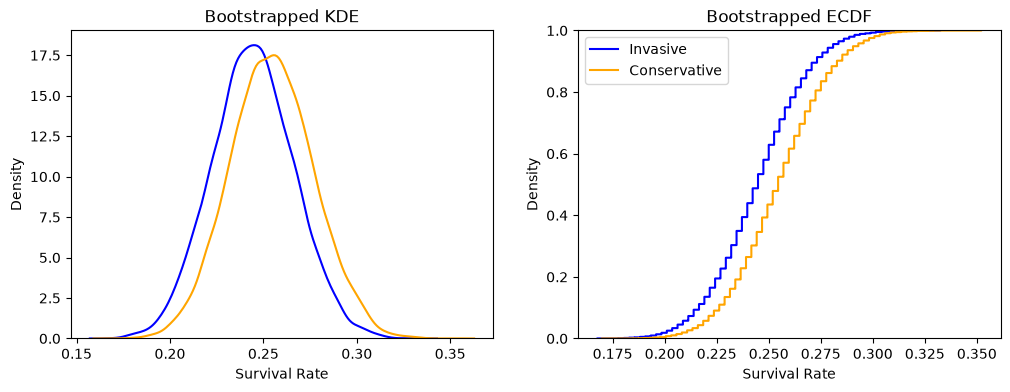

In [5]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))

sns.kdeplot(outcome_a, label='Invasive', color='blue', ax=ax[0])
sns.kdeplot(outcome_b, label='Conservative', color='orange', ax=ax[0]).set(title='Bootstrapped KDE', xlabel='Survival Rate', ylabel='Density')

sns.ecdfplot(outcome_a, label='Invasive', color='blue', ax=ax[1])
sns.ecdfplot(outcome_b, label='Conservative', color='orange', ax=ax[1]).set(title='Bootstrapped ECDF', xlabel='Survival Rate', ylabel='Density')

plt.legend()
plt.show()

**4.** Make a plot of the KDE and ECDF for the ATE. 

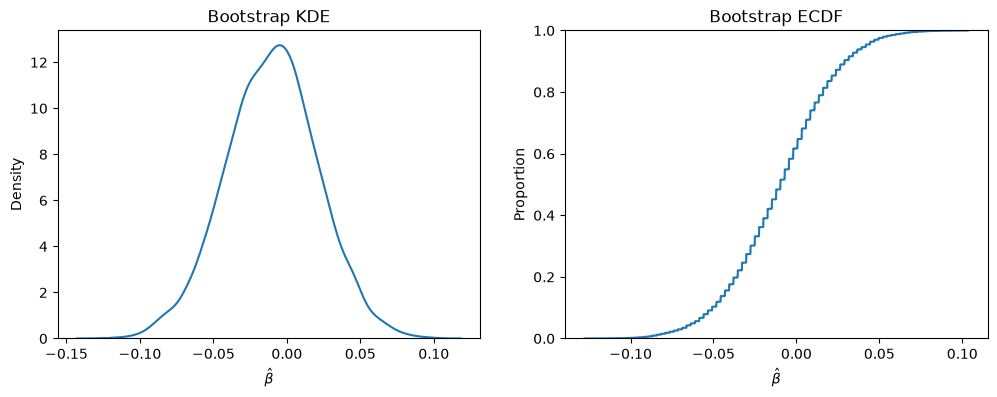

In [6]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))

## KDE
sns.kdeplot(ate, ax=ax[0])
ax[0].set_xlabel(r"$\hat{\beta}$")
ax[0].set_title("Bootstrap KDE")

## ECDF
sns.ecdfplot(ate, ax=ax[1])
ax[1].set_xlabel(r"$\hat{\beta}$")
ax[1].set_title("Bootstrap ECDF")

plt.show()


**5.** Compute 90%, 95%, and 99% confidence intervals for the ATE. Is zero in those intervals? For which do we "fail to reject the null hypothesis that the effect size is zero" and for which do we "reject the null hypothesis that the effect size zero"?

#### all three of the intervals contain zero, which means that we would fail to reject the null hypothesis.

In [7]:
ci90 = np.quantile(ate, [.05, .95])
ci95 = np.quantile(ate, [.025, .975])
ci99 = np.quantile(ate, [.005, .995])

print(f"90% CI: {ci90}")
print(f"95% CI: {ci95}")
print(f"99% CI: {ci99}")

90% CI: [-0.06117357  0.04182016]
95% CI: [-0.07395383  0.04961191]
99% CI: [-0.09200835  0.07017071]


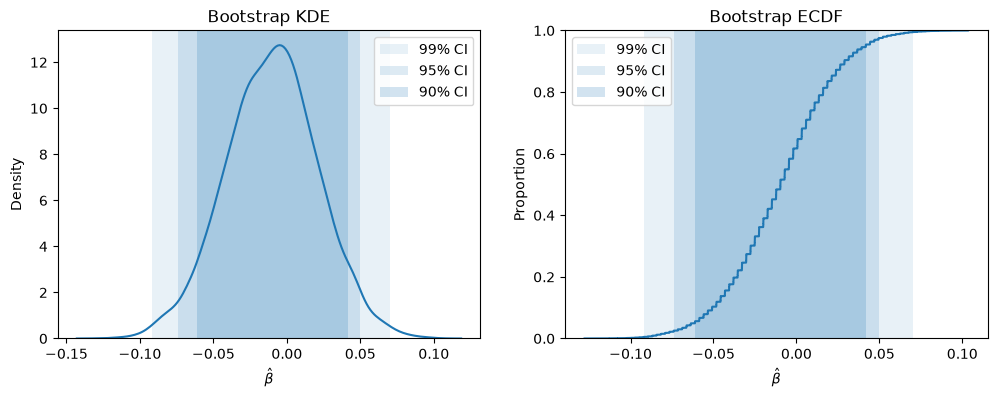

In [8]:
# Percentile bootstrap confidence intervals
ci90 = np.quantile(ate, [.05, .95])
ci95 = np.quantile(ate, [.025, .975])
ci99 = np.quantile(ate, [.005, .995])

fig, ax = plt.subplots(1, 2, figsize=(12, 4))

## KDE
sns.kdeplot(ate, ax=ax[0])

ax[0].axvspan(ci99[0], ci99[1], alpha=0.10, label="99% CI")
ax[0].axvspan(ci95[0], ci95[1], alpha=0.15, label="95% CI")
ax[0].axvspan(ci90[0], ci90[1], alpha=0.20, label="90% CI")

ax[0].set_xlabel(r"$\hat{\beta}$")
ax[0].set_title("Bootstrap KDE")
ax[0].legend()

## ECDF
sns.ecdfplot(ate, ax=ax[1])

ax[1].axvspan(ci99[0], ci99[1], alpha=0.10, label="99% CI")
ax[1].axvspan(ci95[0], ci95[1], alpha=0.15, label="95% CI")
ax[1].axvspan(ci90[0], ci90[1], alpha=0.20, label="90% CI")

ax[1].set_xlabel(r"$\hat{\beta}$")
ax[1].set_title("Bootstrap ECDF")
ax[1].legend()

**6.** What have we learned about inserting balloons into hearts?

#### I learned that this trial did not provide any evidence that the balloon pump invasive method improves survival. The ATE was negative, but also the confidence interval was very wide which ended up including zero, meaning from this we cannot conclude the effect of the pump method. 

# Part 2

In `./data/diabetes.csv`, there is data from a clinical trial considering three treatments for pre-diabetics to reduce the progression to full diabetes: metformin, rosiglitazone, and lifestyle adjustments (diet, exercise). Unlike Part 1, there aren't two treatment arms (i.e. A = aortic balloon, B = no aortic balloon), but three (met, rosi, lifestyle).

You are a data analyst working for `clinicaltrials.gov` and the FDA to provide an unbiased review of the trial's results. The researchers have provided you with `./data/diabests.csv`.

In an ipynb or py file:

1. Load the `./data/diabetes.csv` data. Cross tabulate the outcomes for the three groups. What are the average outcomes for the three groups? 
2. Bootstrap the outcomes for the three groups 10,000 times. Store all of these estimates. As this is another randomized controlled trial, do the resampling within the arms. 
3. Plot the three densities on one plot and three distributions on another. Describe any patterns you see.
4. There are three treatment effects: met versus rosi, met versus lifestyle, rosi versus lifestyle. Make KDE and ECDF plots of all these comparisons.
5. Compute confidence intervals for each pairwise ATE based on its ECDF (percentile bootstrap). Do you find any statistically significant differences between the interventions? Which seems the most effective?

Then:

6. Write a short report (3-5 paragraphs) that summarizes the evidence from the trial for adopting each of the interventions or not. Use tables and visualizations. Write in a professional tone for a technical audience, and focus on evidence (or the lack thereof). Do not assume anyone has read your work in your notebooks.

In [10]:
# here is where i am loading in the table, cross tabulating the outcomes, and finding the average
diabetes = pd.read_csv('../data/diabetes.csv')
diabetes['success'] = (diabetes['outcome'] == 'success').astype(int)

outcome_table = pd.crosstab(diabetes['treatment'], diabetes['outcome'])
average_outcomes = diabetes.groupby('treatment')['success'].agg(['count', 'sum', 'mean'])
average_outcomes = average_outcomes.rename(columns={'count': 'n', 'sum': 'successes', 'mean': 'success_rate'})

display(outcome_table)
display(average_outcomes)

outcome,failure,success
treatment,,
lifestyle,109,125
met,120,112
rosi,90,143


,n,successes,success_rate
treatment,,,
lifestyle,234,125,0.534188
met,232,112,0.482759
rosi,233,143,0.613734


In [11]:
# here i am bootstrapping the outcomes
R = 10_000
rng = np.random.default_rng(42)  # Makes the bootstrap results reproducible
treatments = ['met', 'rosi', 'lifestyle']
groups = {t: diabetes.loc[diabetes['treatment'] == t, 'success'].to_numpy() for t in treatments}

boot_outcomes = {}
for treatment, outcomes in groups.items():
    samples = rng.choice(outcomes, size=(R, len(outcomes)), replace=True)
    boot_outcomes[treatment] = samples.mean(axis=1)

# Had some help from claude for this portion
# Pairwise ATEs: first-listed treatment minus second-listed treatment.
pairwise_ates = {
    'met − rosi': boot_outcomes['met'] - boot_outcomes['rosi'],
    'met − lifestyle': boot_outcomes['met'] - boot_outcomes['lifestyle'],
    'rosi − lifestyle': boot_outcomes['rosi'] - boot_outcomes['lifestyle'],
}

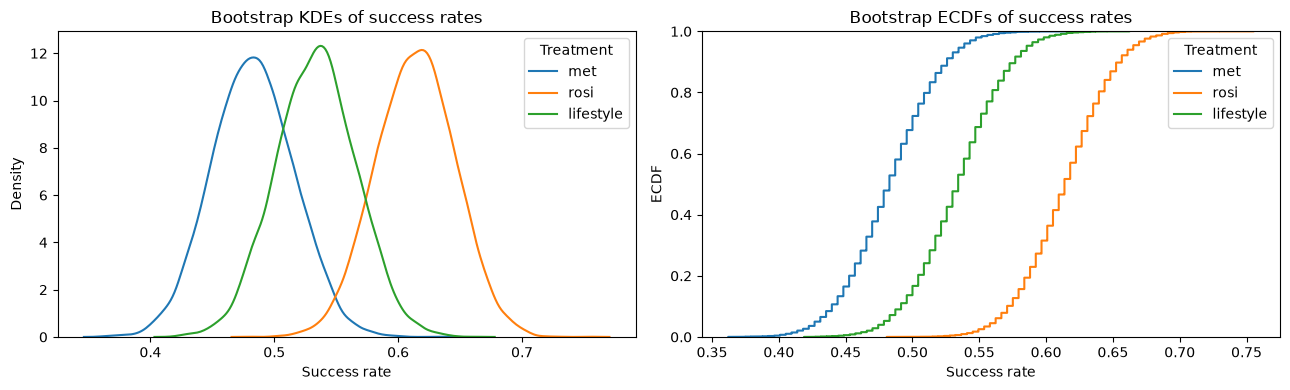

In [12]:
# Bootstrap distributions for the three average outcomes.
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
colors = {'met': 'tab:blue', 'rosi': 'tab:orange', 'lifestyle': 'tab:green'}

for treatment in treatments:
    sns.kdeplot(boot_outcomes[treatment], label=treatment, color=colors[treatment], ax=ax[0])
    sns.ecdfplot(boot_outcomes[treatment], label=treatment, color=colors[treatment], ax=ax[1])

ax[0].set(title='Bootstrap KDEs of success rates', xlabel='Success rate', ylabel='Density')
ax[1].set(title='Bootstrap ECDFs of success rates', xlabel='Success rate', ylabel='ECDF')
for axis in ax:
    axis.legend(title='Treatment')
plt.tight_layout()
plt.show()

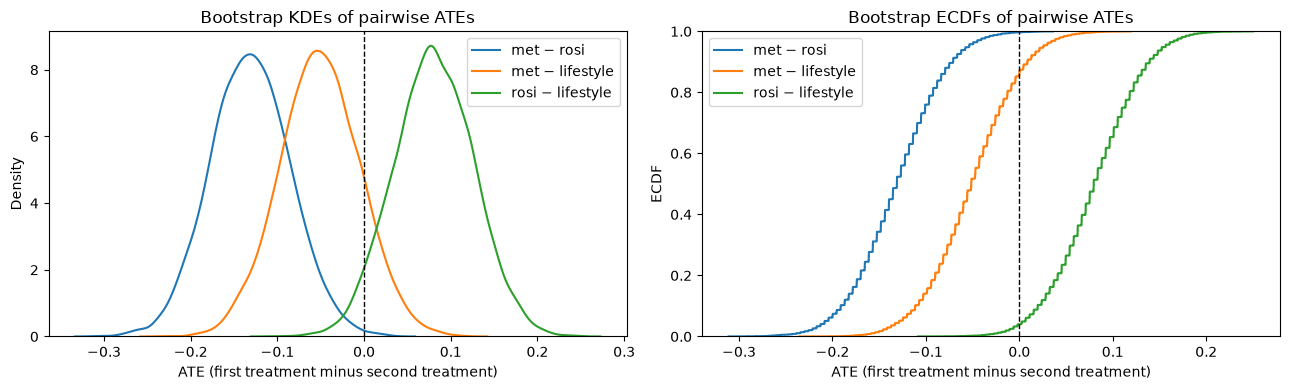

In [ ]:
# plotting the KDE and ECDF plots for all the the pairwise treatment effects
fig, ax = plt.subplots(1, 2, figsize=(13, 4))

for comparison, estimates in pairwise_ates.items():
    sns.kdeplot(estimates, label=comparison, ax=ax[0])
    sns.ecdfplot(estimates, label=comparison, ax=ax[1])

for axis, title, ylabel in zip(ax, ['Bootstrap KDEs of pairwise ATEs', 'Bootstrap ECDFs of pairwise ATEs'], ['Density', 'ECDF']):
    axis.axvline(0, color='black', linestyle='--', linewidth=1)
    axis.set(title=title, xlabel='ATE (first treatment minus second treatment)', ylabel=ylabel)
    axis.legend()
plt.tight_layout()
plt.show()

In [18]:
# finding the 95% confidence intervals
point_estimates = {
    'met − rosi': groups['met'].mean() - groups['rosi'].mean(),
    'met − lifestyle': groups['met'].mean() - groups['lifestyle'].mean(),
    'rosi − lifestyle': groups['rosi'].mean() - groups['lifestyle'].mean(),
}

ci_table = pd.DataFrame([
    {
        'comparison': comparison,
        '95% CI lower': np.quantile(estimates, 0.025),
        '95% CI upper': np.quantile(estimates, 0.975),
    }
    for comparison, estimates in pairwise_ates.items()
])
display(ci_table.round(3))

,comparison,95% CI lower,95% CI upper
0,met − rosi,-0.221,-0.041
1,met − lifestyle,-0.142,0.039
2,rosi − lifestyle,-0.006,0.170


#### the rosi is the only one that is statistically significant from my trials, meaning that it provided evidence of having an altering effect on patients. 

My randomized clinical trail had the purpose of comparign metformin, rosiglitazone, and liefstyle modification to see whether they had effects on preventing progression in diabetes condition.Metformin has a observed surccess rate of 48.3%, while rosiglitazone had a 61.4% and lifestyle modification with 53.5%. rosiglitazone contianed the highest observed average outcome, whereas metformin the the lowest. 

The bootstrap density and ECDF plots had rosiglitazone consistently higher in terms of success rate than the other two methods. The bootstrap distributions for metformin and lifestyle seemed to overlab quite a bit, which shows uncertainity about if their true success rates would even differ. 

Rosiglatazone was higher than metformin by about 13.1 percent, as its 95% percentile-boostrap confidence inteval didn't include zero which provides evidence of a difference between interventions. The remaining two methods did include zero in their intervals which means that my trial did not establish a difference for them at the 5% significance level. 

With all this in mind, the trial supports rosiglitazone as the best method to slow down development in diabetes.